In [36]:
from sklearn.datasets import fetch_california_housing

housing = fetch_california_housing(as_frame=True)
data, target = housing.data, housing.target

In [37]:
target

0        4.526
1        3.585
2        3.521
3        3.413
4        3.422
         ...  
20635    0.781
20636    0.771
20637    0.923
20638    0.847
20639    0.894
Name: MedHouseVal, Length: 20640, dtype: float64

In [38]:
from sklearn.tree import DecisionTreeRegressor

regressor = DecisionTreeRegressor(random_state=42)
regressor.fit(data, target)

DecisionTreeRegressor(random_state=42)

In [39]:
from sklearn.metrics import mean_absolute_error

target_predicted = regressor.predict(data)
score = mean_absolute_error(target, target_predicted)
print(f"On average, our regressor makes an error of {score:.2f}")

On average, our regressor makes an error of 0.00


In [40]:
from sklearn.model_selection import train_test_split

data_train, data_test, target_train, target_test = train_test_split(
  data, target, random_state=0
)

regressor.fit(data_train, target_train)

target_predicted = regressor.predict(data_train)
score = mean_absolute_error(target_train, target_predicted)
print(f"The training error of our model is {score:.2f}")

The training error of our model is 0.00


In [41]:
target_predicted = regressor.predict(data_test)
score = mean_absolute_error(target_test, target_predicted)
print(f"The training error of our model is {score:.2f}")

The training error of our model is 0.47


In [42]:
from sklearn.model_selection import cross_validate
from sklearn.model_selection import ShuffleSplit

cv = ShuffleSplit(n_splits=40, test_size=0.3, random_state=0)
cv_results = cross_validate(
    regressor, data, target, cv=cv, scoring="neg_mean_absolute_error"
)
print(cv_results)

{'fit_time': array([0.13986874, 0.13775086, 0.13908482, 0.13159513, 0.13869977,
       0.13749504, 0.1365571 , 0.13720441, 0.12809229, 0.1267333 ,
       0.12762737, 0.13312769, 0.12654018, 0.12613225, 0.13157654,
       0.12609363, 0.12735057, 0.12794399, 0.12255001, 0.12575269,
       0.12861395, 0.12712622, 0.12919784, 0.13432789, 0.12588191,
       0.12623477, 0.12810588, 0.12668729, 0.12915087, 0.12591171,
       0.13167977, 0.12817597, 0.12816   , 0.13068676, 0.13154936,
       0.12722754, 0.12789512, 0.12538838, 0.12545681, 0.12565422]), 'score_time': array([0.00200009, 0.00199986, 0.00199986, 0.00305367, 0.00240564,
       0.00300002, 0.00300074, 0.00300121, 0.0021162 , 0.00200009,
       0.00250793, 0.00250435, 0.00255346, 0.00200272, 0.00303769,
       0.00253153, 0.00200295, 0.00200272, 0.00485539, 0.00199986,
       0.00250721, 0.00300002, 0.        , 0.00214696, 0.00199866,
       0.00300527, 0.00300074, 0.00199986, 0.00299978, 0.00299764,
       0.00200534, 0.00200725, 0.

In [43]:
import pandas as pd

cv_results = pd.DataFrame(cv_results)
cv_results

,fit_time,score_time,test_score
0,0.139869,0.002000,-0.467812
1,0.137751,0.002000,-0.462452
2,0.139085,0.002000,-0.475007
3,0.131595,0.003054,-0.448174
4,0.138700,0.002406,-0.473033
5,0.137495,0.003000,-0.460263
6,0.136557,0.003001,-0.469139
7,0.137204,0.003001,-0.460607
8,0.128092,0.002116,-0.453734
9,0.126733,0.002000,-0.450740


In [44]:
cv_results["test_error"] = -cv_results["test_score"]

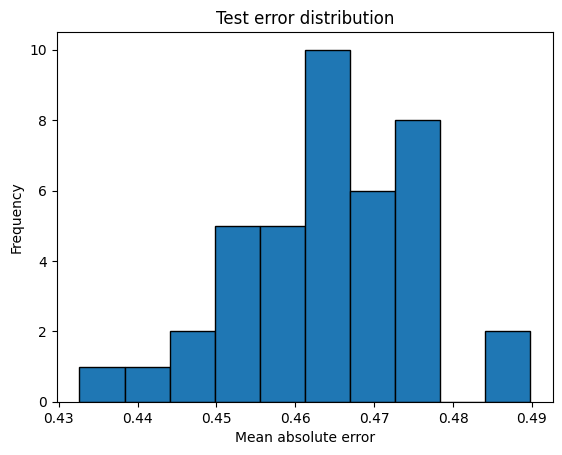

In [46]:
import matplotlib.pyplot as plt

cv_results["test_error"].plot.hist(bins=10, edgecolor="black")
plt.xlabel("Mean absolute error")
_ = plt.title("Test error distribution")

In [47]:
print(
    "The mean cross-validated testing error is: "
    f"{cv_results['test_error'].mean():.2f} with standard deviation of {cv_results['test_error'].std():.2f}"
)

The mean cross-validated testing error is: 0.46 with standard deviation of 0.01


In [48]:
cv_results = cross_validate(regressor, data, target, return_estimator=True)
cv_results

{'fit_time': array([0.16756177, 0.15622997, 0.16012859, 0.16209316, 0.1467824 ]),
 'score_time': array([0.00246263, 0.00150633, 0.00151157, 0.00247145, 0.002002  ]),
 'estimator': [DecisionTreeRegressor(random_state=42),
  DecisionTreeRegressor(random_state=42),
  DecisionTreeRegressor(random_state=42),
  DecisionTreeRegressor(random_state=42),
  DecisionTreeRegressor(random_state=42)],
 'test_score': array([0.27093461, 0.41372445, 0.43912441, 0.23566991, 0.41875969])}